# Customer Repurchase Propensity
## 01 — Data Understanding

**Objective:** inspect the structure and quality of the transaction dataset before making cleaning decisions.

This notebook focuses on understanding the available data. No records are removed or modified in this stage.

## 1. Setup and data loading

Import the libraries, locate the raw Excel file and load the first worksheet.

In [3]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

RANDOM_STATE = 42
DATA_DIR = Path("../data/raw")

raw_files = sorted(DATA_DIR.glob("*.xlsx"))
if not raw_files:
    raise FileNotFoundError(f"No .xlsx files found in {DATA_DIR.resolve()}")

file_path = raw_files[0]
print(f"Dataset file: {file_path.name}")
print(f"File size: {file_path.stat().st_size / (1024 ** 2):.2f} MB")

df = pd.read_excel(file_path)
print(f"Dataset shape: {df.shape[0]:,} rows × {df.shape[1]} columns")
display(df.head())

Dataset file: base.xlsx.xlsx
File size: 43.51 MB
Dataset shape: 525,461 rows × 8 columns


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


## 2. Dataset overview

Review column types, missing values, exact duplicate rows, date coverage and numeric distributions.

In [4]:
print("Column information:")
df.info()

missing_summary = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2),
}).sort_values("missing_count", ascending=False)

print("\nMissing values by column:")
display(missing_summary)

print(f"\nExact duplicate rows: {df.duplicated().sum():,}")
print(f"Date range: {df['InvoiceDate'].min()} to {df['InvoiceDate'].max()}")

print("\nNumeric column summary:")
display(df[["Quantity", "Price"]].describe().T)

Column information:
<class 'pandas.DataFrame'>
RangeIndex: 525461 entries, 0 to 525460
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   Invoice      525461 non-null  object        
 1   StockCode    525461 non-null  object        
 2   Description  522533 non-null  object        
 3   Quantity     525461 non-null  int64         
 4   InvoiceDate  525461 non-null  datetime64[us]
 5   Price        525461 non-null  float64       
 6   Customer ID  417534 non-null  float64       
 7   Country      525461 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 32.1+ MB

Missing values by column:


,missing_count,missing_percent
Customer ID,107927,20.54
Description,2928,0.56
StockCode,0,0.00
Invoice,0,0.00
Quantity,0,0.00
InvoiceDate,0,0.00
Price,0,0.00
Country,0,0.00



Exact duplicate rows: 6,865
Date range: 2009-12-01 07:45:00 to 2010-12-09 20:01:00

Numeric column summary:


,count,mean,std,min,25%,50%,75%,max
Quantity,525461.0,10.337667,107.424110,-9600.00,1.00,3.0,10.00,19152.00
Price,525461.0,4.688834,146.126914,-53594.36,1.25,2.1,4.21,25111.09


## 3. Transaction data quality checks

Negative quantities may be associated with returns or cancellations. Negative prices and invoice identifiers with a `C` prefix also need investigation. These checks are descriptive only: do not remove records based on these results alone.

In [5]:
invoice_is_cancellation = df["Invoice"].astype(str).str.startswith("C")
quality_summary = pd.DataFrame({
    "check": [
        "Invoices with C prefix",
        "Rows with negative quantity",
        "Rows with negative price",
        "Rows with zero quantity",
        "Rows with zero price",
    ],
    "row_count": [
        invoice_is_cancellation.sum(),
        (df["Quantity"] < 0).sum(),
        (df["Price"] < 0).sum(),
        (df["Quantity"] == 0).sum(),
        (df["Price"] == 0).sum(),
    ],
})
quality_summary["percent_of_rows"] = (quality_summary["row_count"] / len(df) * 100).round(2)
display(quality_summary)

print("Example rows with negative quantities:")
display(
    df.loc[
        df["Quantity"] < 0,
        ["Invoice", "StockCode", "Quantity", "InvoiceDate", "Price", "Customer ID", "Country"],
    ].head(10)
)

,check,row_count,percent_of_rows
0,Invoices with C prefix,10206,1.94
1,Rows with negative quantity,12326,2.35
2,Rows with negative price,3,0.00
3,Rows with zero quantity,0,0.00
4,Rows with zero price,3687,0.70


Example rows with negative quantities:


,Invoice,StockCode,Quantity,InvoiceDate,Price,Customer ID,Country
178,C489449,22087,-12,2009-12-01 10:33:00,2.95,16321.0,Australia
179,C489449,85206A,-6,2009-12-01 10:33:00,1.65,16321.0,Australia
180,C489449,21895,-4,2009-12-01 10:33:00,4.25,16321.0,Australia
181,C489449,21896,-6,2009-12-01 10:33:00,2.10,16321.0,Australia
182,C489449,22083,-12,2009-12-01 10:33:00,2.95,16321.0,Australia
183,C489449,21871,-12,2009-12-01 10:33:00,1.25,16321.0,Australia
184,C489449,84946,-12,2009-12-01 10:33:00,1.25,16321.0,Australia
185,C489449,84970S,-24,2009-12-01 10:33:00,0.85,16321.0,Australia
186,C489449,22090,-12,2009-12-01 10:33:00,2.95,16321.0,Australia
196,C489459,90200A,-3,2009-12-01 10:44:00,4.25,17592.0,United Kingdom


In [6]:

# Compare cancellation invoices with negative quantities
invoice_is_cancellation = (
    df["Invoice"].astype(str).str.startswith("C")
)

negative_quantity = df["Quantity"] < 0

print(f"Cancellation invoices: {invoice_is_cancellation.sum():,}")
print(f"Rows with negative quantity: {negative_quantity.sum():,}")
print(
    "Rows matching both conditions: "
    f"{(invoice_is_cancellation & negative_quantity).sum():,}"
)

# Inspect cancellation invoice examples
display(
    df.loc[
        invoice_is_cancellation,
        ["Invoice", "InvoiceDate", "Customer ID", "Quantity", "Price"]
    ].head(10)
)


Cancellation invoices: 10,206
Rows with negative quantity: 12,326
Rows matching both conditions: 10,205


,Invoice,InvoiceDate,Customer ID,Quantity,Price
178,C489449,2009-12-01 10:33:00,16321.0,-12,2.95
179,C489449,2009-12-01 10:33:00,16321.0,-6,1.65
180,C489449,2009-12-01 10:33:00,16321.0,-4,4.25
181,C489449,2009-12-01 10:33:00,16321.0,-6,2.10
182,C489449,2009-12-01 10:33:00,16321.0,-12,2.95
183,C489449,2009-12-01 10:33:00,16321.0,-12,1.25
184,C489449,2009-12-01 10:33:00,16321.0,-12,1.25
185,C489449,2009-12-01 10:33:00,16321.0,-24,0.85
186,C489449,2009-12-01 10:33:00,16321.0,-12,2.95
196,C489459,2009-12-01 10:44:00,17592.0,-3,4.25


## 4. Transaction Pattern Analysis


In [7]:
# Analyze transaction patterns
print("Unique invoices:", df["Invoice"].nunique())
print("Unique products:", df["StockCode"].nunique())
print("Unique customers:", df["Customer ID"].nunique())
print("Unique countries:", df["Country"].nunique())

print("\nInvoice date range:")
print("Start:", df["InvoiceDate"].min())
print("End:", df["InvoiceDate"].max())

print("\nCustomer ID availability:")
print("Rows with customer ID:", df["Customer ID"].notna().sum())
print("Rows without customer ID:", df["Customer ID"].isna().sum())


Unique invoices: 28816
Unique products: 4632
Unique customers: 4383
Unique countries: 40

Invoice date range:
Start: 2009-12-01 07:45:00
End: 2010-12-09 20:01:00

Customer ID availability:
Rows with customer ID: 417534
Rows without customer ID: 107927



## 5. Customer Purchase Frequency


In [8]:
# Identify customer purchase frequency
customer_transactions = df.loc[
    df["Customer ID"].notna()
    & ~df["Invoice"].astype(str).str.startswith("C")
    & (df["Quantity"] > 0)
]

invoices_per_customer = (
    customer_transactions
    .groupby("Customer ID")["Invoice"]
    .nunique()
)

# Summarize the number of invoices per customer
display(invoices_per_customer.describe().to_frame("invoice_count"))

# Classify customers by the number of distinct invoices
customer_frequency = pd.Series({
    "One invoice": (invoices_per_customer == 1).sum(),
    "Multiple invoices": (invoices_per_customer > 1).sum()
})

customer_frequency = customer_frequency.to_frame("customer_count")
customer_frequency["percentage"] = (
    customer_frequency["customer_count"]
    / len(invoices_per_customer) * 100
).round(2)

display(customer_frequency)


,invoice_count
count,4314.000000
mean,4.454103
std,8.168658
min,1.000000
25%,1.000000
50%,2.000000
75%,5.000000
max,205.000000


,customer_count,percentage
One invoice,1421,32.94
Multiple invoices,2893,67.06



## 6. Distribution of Customer Purchase Frequency


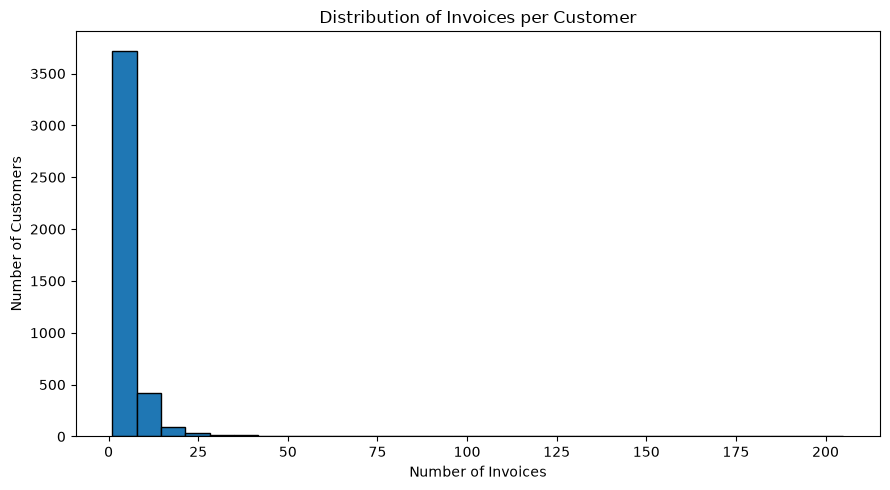

In [9]:
import matplotlib.pyplot as plt

# Plot the distribution of invoices per customer
plt.figure(figsize=(9, 5))

plt.hist(
    invoices_per_customer,
    bins=30,
    edgecolor="black"
)

plt.title("Distribution of Invoices per Customer")
plt.xlabel("Number of Invoices")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()



## 7. Customer Recency Analysis


,days_since_last_purchase
count,4314.000000
mean,91.269124
std,96.943482
min,1.000000
25%,18.000000
50%,53.000000
75%,136.000000
max,374.000000


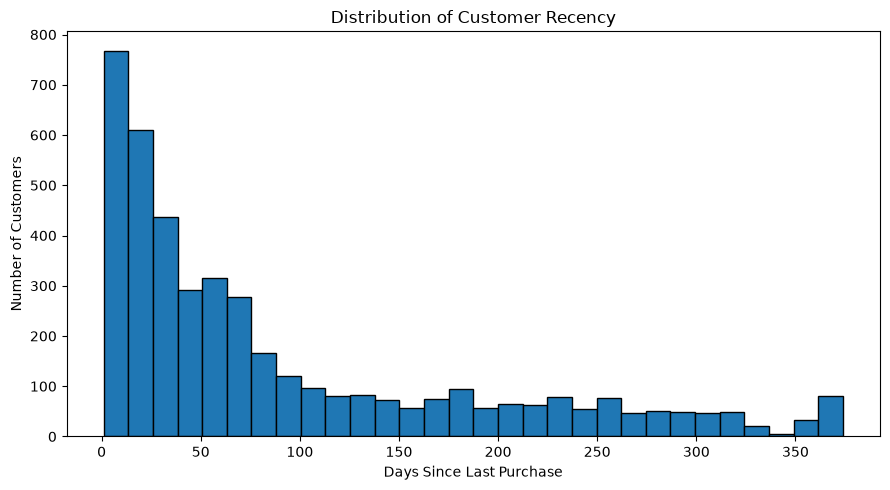

In [11]:
# Calculate the last purchase date for each customer
customer_last_purchase = (
    customer_transactions
    .groupby("Customer ID")["InvoiceDate"]
    .max()
)

# Calculate days since the last purchase in the dataset
reference_date = df["InvoiceDate"].max() + pd.Timedelta(days=1)

customer_recency = (
    reference_date - customer_last_purchase
).dt.days

# Summarize customer recency
display(customer_recency.describe().to_frame("days_since_last_purchase"))

# Plot the distribution of customer recency
plt.figure(figsize=(9, 5))
plt.hist(customer_recency, bins=30, edgecolor="black")
plt.title("Distribution of Customer Recency")
plt.xlabel("Days Since Last Purchase")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()



## 8. Monthly Purchase Activity


In [13]:
# Analyze monthly purchase activity
monthly_activity = (
    customer_transactions
    .assign(
        month=customer_transactions["InvoiceDate"].dt.to_period("M")
    )
    .groupby("month")
    .agg(
        invoice_count=("Invoice", "nunique"),
        customer_count=("Customer ID", "nunique"),
        transaction_rows=("Invoice", "size")
    )
    .reset_index()
)

monthly_activity["month"] = monthly_activity["month"].astype(str)

display(monthly_activity)


,month,invoice_count,customer_count,transaction_rows
0,2009-12,1512,955,30761
1,2010-01,1011,720,21778
2,2010-02,1106,774,23369
3,2010-03,1524,1057,32302
4,2010-04,1329,942,27238
5,2010-05,1377,966,28644
6,2010-06,1497,1041,31191
7,2010-07,1381,928,27033
8,2010-08,1293,911,26393
9,2010-09,1689,1145,34602



## 9. Temporal Split Definition


In [15]:
# Define the historical and prediction windows
cutoff_date = pd.Timestamp("2010-09-09")
prediction_end = pd.Timestamp("2010-12-10")

# Keep identified customers and positive-quantity transactions
valid_transactions = df.loc[
    df["Customer ID"].notna()
    & ~df["Invoice"].astype(str).str.startswith("C")
    & (df["Quantity"] > 0)
].copy()

# Split transactions into historical and prediction windows
historical_transactions = valid_transactions.loc[
    valid_transactions["InvoiceDate"] < cutoff_date
].copy()

future_transactions = valid_transactions.loc[
    (valid_transactions["InvoiceDate"] >= cutoff_date)
    & (valid_transactions["InvoiceDate"] < prediction_end)
].copy()

print("Historical period:")
print(historical_transactions["InvoiceDate"].min())
print(historical_transactions["InvoiceDate"].max())
print("Historical rows:", len(historical_transactions))

print("\nPrediction period:")
print(future_transactions["InvoiceDate"].min())
print(future_transactions["InvoiceDate"].max())
print("Prediction rows:", len(future_transactions))


Historical period:
2009-12-01 07:45:00
2010-09-08 17:23:00
Historical rows: 255091

Prediction period:
2010-09-09 10:37:00
2010-12-09 20:01:00
Prediction rows: 152604



## 10. Customer Features and Target


In [16]:
# Build customer-level features from historical transactions
customer_features = (
    historical_transactions
    .groupby("Customer ID")
    .agg(
        recency_days=(
            "InvoiceDate",
            lambda dates: (cutoff_date - dates.max()).days
        ),
        invoice_count=("Invoice", "nunique"),
        total_quantity=("Quantity", "sum"),
        total_spend=("Price", lambda prices: 0)
    )
)

# Calculate total spend at transaction-line level
historical_transactions = historical_transactions.copy()
historical_transactions["line_total"] = (
    historical_transactions["Quantity"]
    * historical_transactions["Price"]
)

customer_spend = historical_transactions.groupby("Customer ID")["line_total"].sum()
customer_features["total_spend"] = customer_spend

# Create the future repurchase target
future_customers = future_transactions["Customer ID"].unique()

customer_features["repurchased"] = (
    customer_features.index.isin(future_customers).astype(int)
)

display(customer_features.head())
print("\nFeature table shape:", customer_features.shape)
print("\nTarget distribution:")
display(
    customer_features["repurchased"]
    .value_counts()
    .rename(index={0: "No repurchase", 1: "Repurchase"})
    .to_frame("customer_count")
)


,recency_days,invoice_count,total_quantity,total_spend,repurchased
Customer ID,,,,,
12346.0,72,11,70,372.86,0
12349.0,113,2,474,1268.52,1
12355.0,110,1,303,488.21,0
12358.0,93,2,590,1697.93,1
12359.0,78,5,877,2012.03,1



Feature table shape: (3361, 5)

Target distribution:


,customer_count
repurchased,
Repurchase,1951
No repurchase,1410


In [17]:
# Check feature quality
print("Missing values:")
display(customer_features.isna().sum().to_frame("missing_values"))

print("\nFeature summary:")
display(
    customer_features[
        ["recency_days", "invoice_count", "total_quantity", "total_spend"]
    ].describe().T
)

print("\nTarget distribution (%):")
display(
    (customer_features["repurchased"].value_counts(normalize=True) * 100)
    .rename("percentage")
    .round(2)
)


Missing values:


,missing_values
recency_days,0
invoice_count,0
total_quantity,0
total_spend,0
repurchased,0



Feature summary:


,count,mean,std,min,25%,50%,75%,max
recency_days,3361.0,92.847069,76.960614,0.0,27.00,73.00,141.00,281.00
invoice_count,3361.0,3.686105,6.213892,1.0,1.00,2.00,4.00,122.00
total_quantity,3361.0,1091.162154,6045.007471,1.0,130.00,326.00,830.00,220600.00
total_spend,3361.0,1679.524062,7314.580126,0.0,271.47,600.34,1423.05,269041.67



Target distribution (%):


repurchased
1    58.05
0    41.95
Name: percentage, dtype: float64

In [18]:
from pathlib import Path

output_path = Path("../data/processed/customer_features.csv")
output_path.parent.mkdir(parents=True, exist_ok=True)

customer_features.to_csv(output_path, index=True)

print(f"Feature table saved to: {output_path}")

Feature table saved to: ..\data\processed\customer_features.csv
